model: Yolov11 -
dataset: Kvasir(approximately 2000 images)


In [ ]:
# dataset
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="IcaoVX6LiZgV351zO9Y3")
project = rf.workspace("vasudevan-s-7rulx").project("kvasir-smmxr")
version = project.version(11)
dataset = version.download("yolov11")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 302.8/302.8 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 36.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 103.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 4.8 MB/s eta 0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.2
    Uninstalling typer-0.27.2:
      Successfully uninstalled typer-0.27.2
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to kvasir-11 in yolov11:: 100%|██████████| 4476/4476 [00:01<00:00, 4246.66it/s]


In [ ]:
!pip uninstall opencv-python -y
!pip install opencv-python-headless
!pip install ultralytics torch torchvision pillow

Found existing installation: opencv-python 5.0.0.93
Uninstalling opencv-python-5.0.0.93:
  Successfully uninstalled opencv-python-5.0.0.93
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.4/46.4 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 24.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.8/73.8 MB 11.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.4/75.4 kB 7.1 MB/s eta 0:00:00


In [ ]:
from ultralytics import YOLO
import yaml
import torch

# train with data augmentation(to decrease overfitting)

def train(dataset_path, class_names):


    config = {
        'path': dataset_path,
        'train': 'train/images',
        'val': 'valid/images',
        'nc': len(class_names),
        'names': class_names
    }

    with open('dataset_augmented.yaml', 'w') as f:
        yaml.dump(config, f, default_flow_style=False)


    model = YOLO('yolo11n.pt')

    # Training with strong augmentation
    results = model.train(
        data='/content/dataset_augmented.yaml',
        epochs=100,  # More epochs
        imgsz=640,
        batch=16,
        device='cuda' if torch.cuda.is_available() else 'cpu',


        hsv_h=0.015,  # HSV-Hue augmentation
        hsv_s=0.7,    # HSV-Saturation augmentation
        hsv_v=0.4,    # HSV-Value augmentation
        degrees=45.0, # Rotation degrees
        translate=0.2, # Translation
        scale=0.5,    # Scale augmentation
        shear=0.0,    # Shear augmentation
        perspective=0.0005, # Perspective augmentation
        flipud=0.5,   # Flip up-down probability
        fliplr=0.5,   # Flip left-right probability
        mosaic=1.0,   # Mosaic augmentation probability
        mixup=0.2,    # MixUp augmentation probability

        # Regularization
        dropout=0.2,   # Dropout regularization
        weight_decay=0.0005,

        # Learning rate
        lr0=0.01,
        lrf=0.01,

        project='yolo11_augmented',
        name='strong_augmentation',
        exist_ok=True
    )

    return results



Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart#ultralytics-settings.


In [ ]:
from ultralytics import YOLO
import torch

# validation
def validate_model(model_path, data_config):


    model = YOLO(model_path)

    metrics = model.val(
        data=data_config,
        split='val',
        device='cuda' if torch.cuda.is_available() else 'cpu',
        verbose=True
    )

    return metrics



In [ ]:
from ultralytics import YOLO
import torch
import os
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict

# test validation

class TestSetValidator:
    def __init__(self, model_path, test_images_dir, test_labels_dir):
        self.model = YOLO(model_path)
        self.test_images_dir = test_images_dir
        self.test_labels_dir = test_labels_dir
        self.results = {}

    def calculate_iou(self, box1, box2):
        """Calculate Intersection over Union (IoU) between two boxes"""
        x1 = max(box1[0], box2[0])
        y1 = max(box1[1], box2[1])
        x2 = min(box1[2], box2[2])
        y2 = min(box1[3], box2[3])

        intersection = max(0, x2 - x1) * max(0, y2 - y1)
        area1 = (box1[2] - box1[0]) * (box1[3] - box1[1])
        area2 = (box2[2] - box2[0]) * (box2[3] - box2[1])
        union = area1 + area2 - intersection

        return intersection / union if union > 0 else 0

    def yolo_to_absolute(self, yolo_coords, img_width, img_height):
        """Convert YOLO format (normalized center) to absolute coordinates"""
        x_center, y_center, width, height = yolo_coords
        x1 = (x_center - width/2) * img_width
        y1 = (y_center - height/2) * img_height
        x2 = (x_center + width/2) * img_width
        y2 = (y_center + height/2) * img_height
        return [x1, y1, x2, y2]

    def load_ground_truth(self, label_path, img_width, img_height):
        """Load ground truth boxes from YOLO format label file"""
        true_boxes = []
        true_classes = []

        if os.path.exists(label_path):
            with open(label_path, 'r') as f:
                for line in f:
                    parts = line.strip().split()
                    if len(parts) >= 5:
                        class_id = int(parts[0])
                        coords = list(map(float, parts[1:5]))
                        abs_coords = self.yolo_to_absolute(coords, img_width, img_height)
                        true_boxes.append(abs_coords)
                        true_classes.append(class_id)

        return true_boxes, true_classes

    def calculate_metrics_per_image(self, pred_boxes, pred_classes, pred_confs, true_boxes, true_classes, iou_threshold=0.5):
        """Calculate precision, recall, and other metrics for a single image"""
        if len(true_boxes) == 0 and len(pred_boxes) == 0:
            return 1.0, 1.0, 0, 0, 0  # Perfect if no objects and no predictions

        if len(true_boxes) == 0:
            return 0, 0, 0, len(pred_boxes), 0  # All predictions are false positives

        if len(pred_boxes) == 0:
            return 0, 0, 0, 0, len(true_boxes)  # All ground truths are false negatives

        # Calculate IoU matrix
        iou_matrix = np.zeros((len(pred_boxes), len(true_boxes)))
        for i, pred_box in enumerate(pred_boxes):
            for j, true_box in enumerate(true_boxes):
                iou_matrix[i, j] = self.calculate_iou(pred_box, true_box)

        # Find matches based on IoU threshold and class matching
        matches = []
        used_true = set()
        used_pred = set()

        # Sort by IoU in descending order
        for i in range(len(pred_boxes)):
            for j in range(len(true_boxes)):
                if iou_matrix[i, j] >= iou_threshold and pred_classes[i] == true_classes[j]:
                    if j not in used_true and i not in used_pred:
                        matches.append((i, j, iou_matrix[i, j]))
                        used_true.add(j)
                        used_pred.add(i)

        true_positives = len(matches)
        false_positives = len(pred_boxes) - true_positives
        false_negatives = len(true_boxes) - true_positives

        precision = true_positives / (true_positives + false_positives) if (true_positives + false_positives) > 0 else 0
        recall = true_positives / (true_positives + false_negatives) if (true_positives + false_negatives) > 0 else 0

        return precision, recall, true_positives, false_positives, false_negatives

    def run_comprehensive_validation(self, conf_threshold=0.25, iou_threshold=0.5):
        """Run comprehensive validation on test set"""
        test_images = [f for f in os.listdir(self.test_images_dir)
                      if f.lower().endswith(('.jpg', '.jpeg', '.png'))]

        all_metrics = {
            'precisions': [],
            'recalls': [],
            'true_positives': 0,
            'false_positives': 0,
            'false_negatives': 0,
            'class_metrics': defaultdict(lambda: {'tp': 0, 'fp': 0, 'fn': 0}),
            'image_metrics': []
        }

        print(f"Validating on {len(test_images)} test images...")

        for img_name in test_images:
            base_name = os.path.splitext(img_name)[0]
            img_path = os.path.join(self.test_images_dir, img_name)
            label_path = os.path.join(self.test_labels_dir, f'{base_name}.txt')

            # Run prediction
            results = self.model(img_path, conf=conf_threshold, verbose=False)

            # Get image dimensions
            img_width = results[0].orig_shape[1]
            img_height = results[0].orig_shape[0]

            # Get predicted boxes, classes, and confidences
            pred_boxes = []
            pred_classes = []
            pred_confs = []

            if results[0].boxes is not None:
                for box in results[0].boxes:
                    pred_boxes.append(box.xyxy[0].cpu().numpy())
                    pred_classes.append(int(box.cls.item()))
                    pred_confs.append(box.conf.item())

            # Load ground truth
            true_boxes, true_classes = self.load_ground_truth(label_path, img_width, img_height)

            # Calculate metrics for this image
            precision, recall, tp, fp, fn = self.calculate_metrics_per_image(
                pred_boxes, pred_classes, pred_confs, true_boxes, true_classes, iou_threshold
            )

            # Update overall metrics
            all_metrics['precisions'].append(precision)
            all_metrics['recalls'].append(recall)
            all_metrics['true_positives'] += tp
            all_metrics['false_positives'] += fp
            all_metrics['false_negatives'] += fn

            # Update per-class metrics
            for class_id in set(pred_classes + true_classes):
                class_tp = sum(1 for i, pred_class in enumerate(pred_classes)
                             if pred_class == class_id and i in [m[0] for m in self.find_matches(pred_boxes, true_boxes, pred_classes, true_classes, iou_threshold)])
                class_fp = sum(1 for pred_class in pred_classes if pred_class == class_id) - class_tp
                class_fn = sum(1 for true_class in true_classes if true_class == class_id) - class_tp

                all_metrics['class_metrics'][class_id]['tp'] += class_tp
                all_metrics['class_metrics'][class_id]['fp'] += class_fp
                all_metrics['class_metrics'][class_id]['fn'] += class_fn

            # Store per-image metrics
            all_metrics['image_metrics'].append({
                'image': img_name,
                'precision': precision,
                'recall': recall,
                'true_positives': tp,
                'false_positives': fp,
                'false_negatives': fn,
                'predicted_objects': len(pred_boxes),
                'true_objects': len(true_boxes)
            })

        # Calculate overall metrics
        all_metrics['average_precision'] = np.mean(all_metrics['precisions'])
        all_metrics['average_recall'] = np.mean(all_metrics['recalls'])
        all_metrics['f1_score'] = 2 * (all_metrics['average_precision'] * all_metrics['average_recall']) / (
            all_metrics['average_precision'] + all_metrics['average_recall']) if (
            all_metrics['average_precision'] + all_metrics['average_recall']) > 0 else 0

        # Calculate mAP
        all_metrics['map'] = self.calculate_map(all_metrics['precisions'], all_metrics['recalls'])

        self.results = all_metrics
        return all_metrics

    def find_matches(self, pred_boxes, true_boxes, pred_classes, true_classes, iou_threshold):
        """Find matches between predictions and ground truth"""
        matches = []
        iou_matrix = np.zeros((len(pred_boxes), len(true_boxes)))

        for i, pred_box in enumerate(pred_boxes):
            for j, true_box in enumerate(true_boxes):
                if pred_classes[i] == true_classes[j]:
                    iou_matrix[i, j] = self.calculate_iou(pred_box, true_box)

        # Greedy matching
        used_true = set()
        used_pred = set()

        while True:
            max_iou = 0
            best_i, best_j = -1, -1

            for i in range(len(pred_boxes)):
                for j in range(len(true_boxes)):
                    if i not in used_pred and j not in used_true and iou_matrix[i, j] > max_iou:
                        max_iou = iou_matrix[i, j]
                        best_i, best_j = i, j

            if max_iou >= iou_threshold:
                matches.append((best_i, best_j, max_iou))
                used_pred.add(best_i)
                used_true.add(best_j)
            else:
                break

        return matches

    def calculate_map(self, precisions, recalls):
        """Calculate mean Average Precision"""

        return np.mean(precisions)

    def print_detailed_report(self):
        """Print comprehensive validation report"""
        if not self.results:
            print("Run validation first!")
            return

        metrics = self.results

        print("\n" + "="*80)
        print("COMPREHENSIVE TEST SET VALIDATION REPORT")
        print("="*80)

        print(f"\nOverall Metrics:")
        print(f"Average Precision: {metrics['average_precision']:.4f}")
        print(f"Average Recall: {metrics['average_recall']:.4f}")
        print(f"F1 Score: {metrics['f1_score']:.4f}")
        print(f"mAP: {metrics['map']:.4f}")
        print(f"True Positives: {metrics['true_positives']}")
        print(f"False Positives: {metrics['false_positives']}")
        print(f"False Negatives: {metrics['false_negatives']}")

        print(f"\nPer-class Metrics:")
        for class_id, class_metrics in metrics['class_metrics'].items():
            tp = class_metrics['tp']
            fp = class_metrics['fp']
            fn = class_metrics['fn']

            precision = tp / (tp + fp) if (tp + fp) > 0 else 0
            recall = tp / (tp + fn) if (tp + fn) > 0 else 0
            f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0

            print(f"Class {class_id}: Precision={precision:.3f}, Recall={recall:.3f}, F1={f1:.3f}, "
                  f"TP={tp}, FP={fp}, FN={fn}")

        print(f"\nImage Statistics:")
        print(f"Total images: {len(metrics['image_metrics'])}")
        avg_pred = np.mean([img['predicted_objects'] for img in metrics['image_metrics']])
        avg_true = np.mean([img['true_objects'] for img in metrics['image_metrics']])
        print(f"Average predicted objects per image: {avg_pred:.2f}")
        print(f"Average true objects per image: {avg_true:.2f}")

    def plot_metrics_distribution(self):
        """Plot distribution of metrics across images"""
        if not self.results:
            print("Run validation first!")
            return

        metrics = self.results

        fig, axes = plt.subplots(2, 2, figsize=(15, 12))

        # Precision distribution
        axes[0, 0].hist(metrics['precisions'], bins=20, alpha=0.7, color='blue')
        axes[0, 0].set_title('Precision Distribution Across Images')
        axes[0, 0].set_xlabel('Precision')
        axes[0, 0].set_ylabel('Frequency')

        # Recall distribution
        axes[0, 1].hist(metrics['recalls'], bins=20, alpha=0.7, color='green')
        axes[0, 1].set_title('Recall Distribution Across Images')
        axes[0, 1].set_xlabel('Recall')
        axes[0, 1].set_ylabel('Frequency')

        # Objects per image
        pred_counts = [img['predicted_objects'] for img in metrics['image_metrics']]
        true_counts = [img['true_objects'] for img in metrics['image_metrics']]

        axes[1, 0].hist([pred_counts, true_counts], bins=15, alpha=0.7,
                       label=['Predicted', 'True'], color=['orange', 'purple'])
        axes[1, 0].set_title('Objects per Image Distribution')
        axes[1, 0].set_xlabel('Number of Objects')
        axes[1, 0].set_ylabel('Frequency')
        axes[1, 0].legend()

        # Precision-Recall scatter
        axes[1, 1].scatter(metrics['recalls'], metrics['precisions'], alpha=0.6)
        axes[1, 1].set_title('Precision vs Recall')
        axes[1, 1].set_xlabel('Recall')
        axes[1, 1].set_ylabel('Precision')
        axes[1, 1].set_xlim(0, 1)
        axes[1, 1].set_ylim(0, 1)

        plt.tight_layout()
        plt.savefig('test_set_metrics_distribution.png', dpi=300, bbox_inches='tight')
        plt.show()

        print("Metrics distribution plots saved as 'test_set_metrics_distribution.png'")



In [ ]:
train(
    dataset_path='/content/kvasir-11',
    class_names=['esophagitis', 'polyps', 'ulcerative-colitis']
)

Ultralytics 8.4.146 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset_augmented.yaml, degrees=45.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.2, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.2, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=strong_augmentation, nbs=64, nms=None, opse

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7c72b35a27b0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04

In [ ]:

model_path = '/content/runs/detect/yolo11_augmented/strong_augmentation/weights/best.pt'
data_config = '/content/kvasir-11/data.yaml'

metrics = validate_model(model_path, data_config)

Ultralytics 8.4.146 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,582,737 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3060.6±1224.7 MB/s, size: 174.1 KB)
val: Scanning /content/kvasir-11/valid/labels.cache... 463 images, 0 backgrounds, 21 corrupt: 100% ━━━━━━━━━━━━ 463/463 107.9Mit/s 0.0s
val: /content/kvasir-11/valid/images/1515780d-178b-42c7-b621-7ab445e3ad89_jpg.rf.b91a829d30ea77f5ba27f97135b0db98.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: /content/kvasir-11/valid/images/5c0a51a1-a15c-4aea-8d52-9c2c12030c47_jpg.rf.a5cc29e8971b02eef6cb46b6f0c65fb1.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: /content/kvasir-11/valid/images/62bb1119-9682-4577-91e6-f15a2cf36e65_jpg.rf.266a3f35a47e9be4d35eb5cba404f699.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: /content/kvasir-11/valid/images/67475ab5-8be7

Validating on 225 test images...

COMPREHENSIVE TEST SET VALIDATION REPORT

Overall Metrics:
Average Precision: 0.2623
Average Recall: 0.2161
F1 Score: 0.2370
mAP: 0.2623
True Positives: 133
False Positives: 216
False Negatives: 319

Per-class Metrics:
Class 2: Precision=0.540, Recall=0.374, F1=0.442, TP=102, FP=87, FN=171
Class 0: Precision=0.265, Recall=0.239, F1=0.251, TP=22, FP=61, FN=70
Class 1: Precision=0.117, Recall=0.103, F1=0.110, TP=9, FP=68, FN=78

Image Statistics:
Total images: 225
Average predicted objects per image: 1.55
Average true objects per image: 2.01


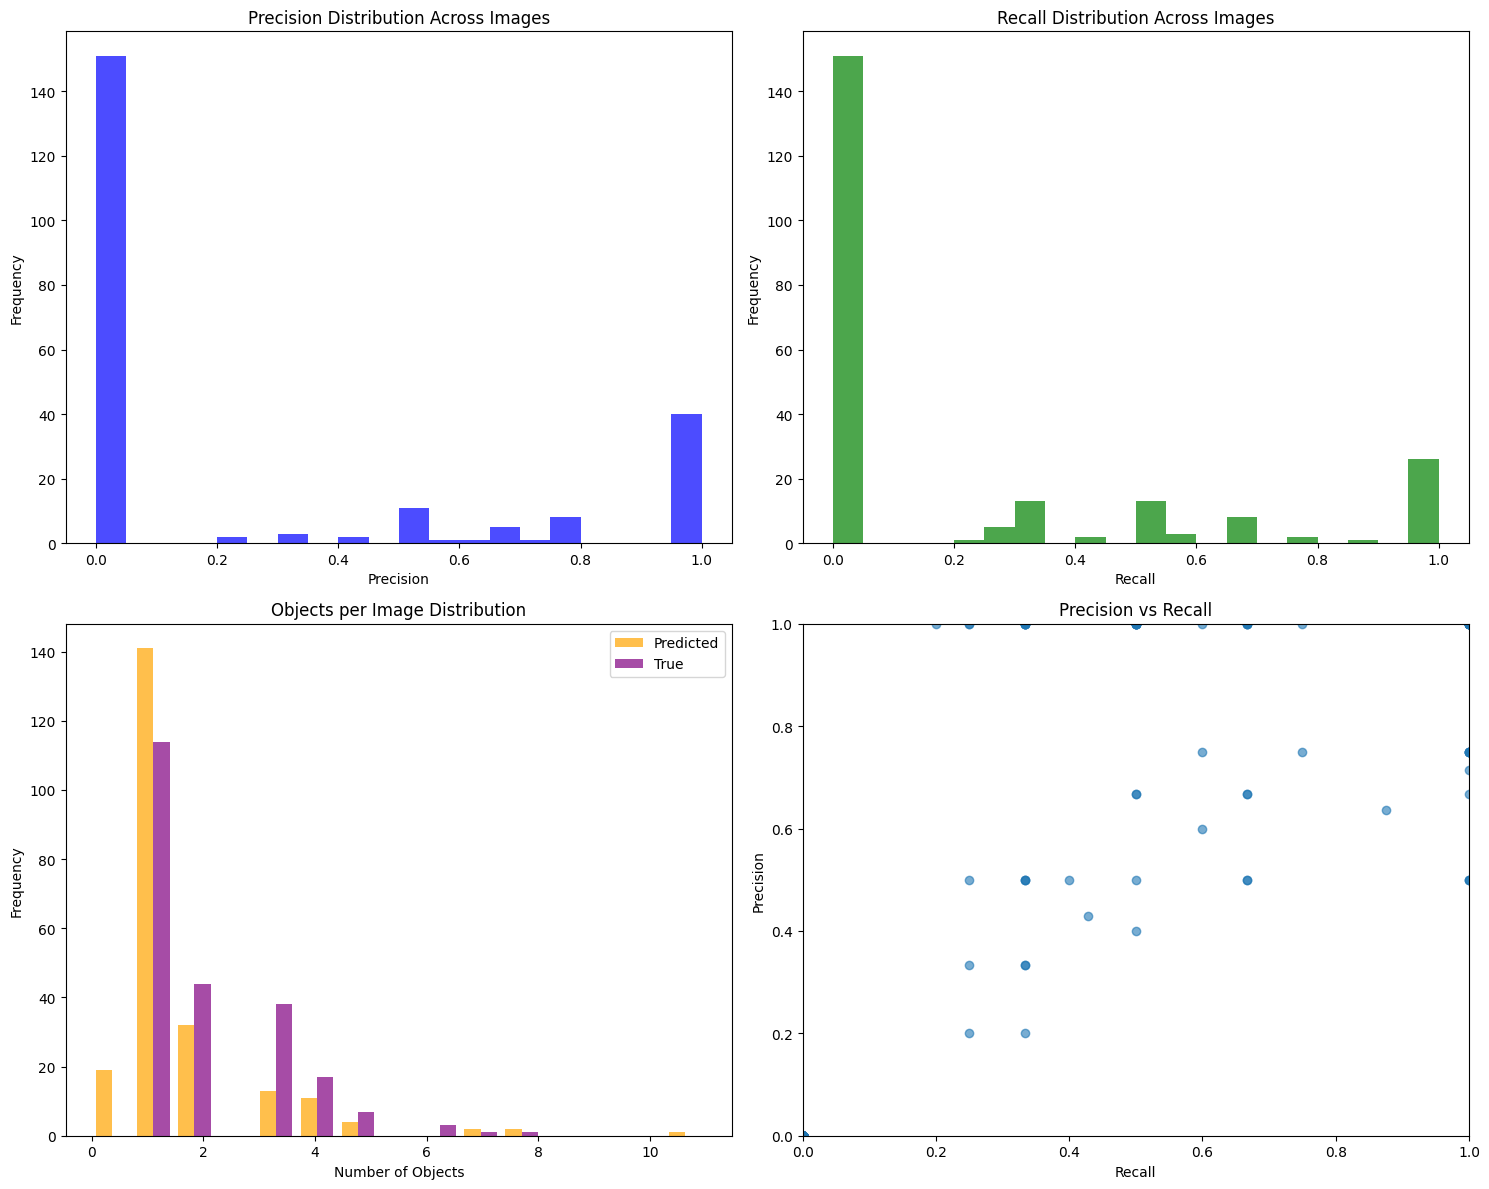

Metrics distribution plots saved as 'test_set_metrics_distribution.png'


In [ ]:
validator = TestSetValidator(
    model_path='/content/runs/detect/yolo11_augmented/strong_augmentation/weights/best.pt',
    test_images_dir='/content/kvasir-11/test/images',
    test_labels_dir='/content/kvasir-11/test/labels'
)

# Run comprehensive validation
metrics = validator.run_comprehensive_validation(conf_threshold=0.25, iou_threshold=0.5)

# Print detailed report
validator.print_detailed_report()

# Plot metrics distribution
validator.plot_metrics_distribution()